In [1]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Load FinBERT (ProsusAI's popular financial sentiment model)
model_name = "ProsusAI/finbert"

print("📡 Fetching FinBERT architecture and weights...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

📡 Fetching FinBERT architecture and weights...


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [2]:
# dir(model)

In [3]:
import torch.nn.functional as F

# 1. Put the model in evaluation mode
model.eval()

# 2. Define your financial text(s) to analyze
headlines = [
    "Quarterly revenue surged 18% year-over-year, easily beating Wall Street estimates.",
    "Operating margins narrowed due to rising raw material costs.",
    "The central bank kept interest rates unchanged at 5.25%."
]

# 3. Tokenize and run through FinBERT
inputs = tokenizer(headlines, padding=True, truncation=True, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs)
    probs = F.softmax(outputs.logits, dim=-1)

# 4. Print clean sentiment predictions
labels = model.config.id2label  # {0: 'positive', 1: 'negative', 2: 'neutral'}

for text, prob_row in zip(headlines, probs):
    top_idx = torch.argmax(prob_row).item()
    print(f"Text       : {text}")
    print(f"Prediction : {labels[top_idx].upper()} ({prob_row[top_idx]*100:.2f}%)")
    print(f"Breakdown  : Positive: {prob_row[0]*100:.1f}% | Negative: {prob_row[1]*100:.1f}% | Neutral: {prob_row[2]*100:.1f}%")
    print("-" * 70)


Text       : Quarterly revenue surged 18% year-over-year, easily beating Wall Street estimates.
Prediction : POSITIVE (95.41%)
Breakdown  : Positive: 95.4% | Negative: 2.2% | Neutral: 2.4%
----------------------------------------------------------------------
Text       : Operating margins narrowed due to rising raw material costs.
Prediction : NEGATIVE (97.23%)
Breakdown  : Positive: 1.2% | Negative: 97.2% | Neutral: 1.6%
----------------------------------------------------------------------
Text       : The central bank kept interest rates unchanged at 5.25%.
Prediction : NEUTRAL (84.20%)
Breakdown  : Positive: 8.5% | Negative: 7.3% | Neutral: 84.2%
----------------------------------------------------------------------


---
# UNDERSTAND The FinBERT AI Model
---

In [4]:
from IPython.display import Image, display

In [5]:
import os
print(os.listdir("/kaggle/input/datasets/silentmonk2026/finbert-imgs"))
img_dir = r"/kaggle/input/datasets/silentmonk2026/finbert-imgs/"
print(img_dir)

['image_1.png', 'image_2.png', 'image_3.png', 'image_4.png', 'image_5.png', 'image_6.jpg', 'image_7.jpg']
/kaggle/input/datasets/silentmonk2026/finbert-imgs/


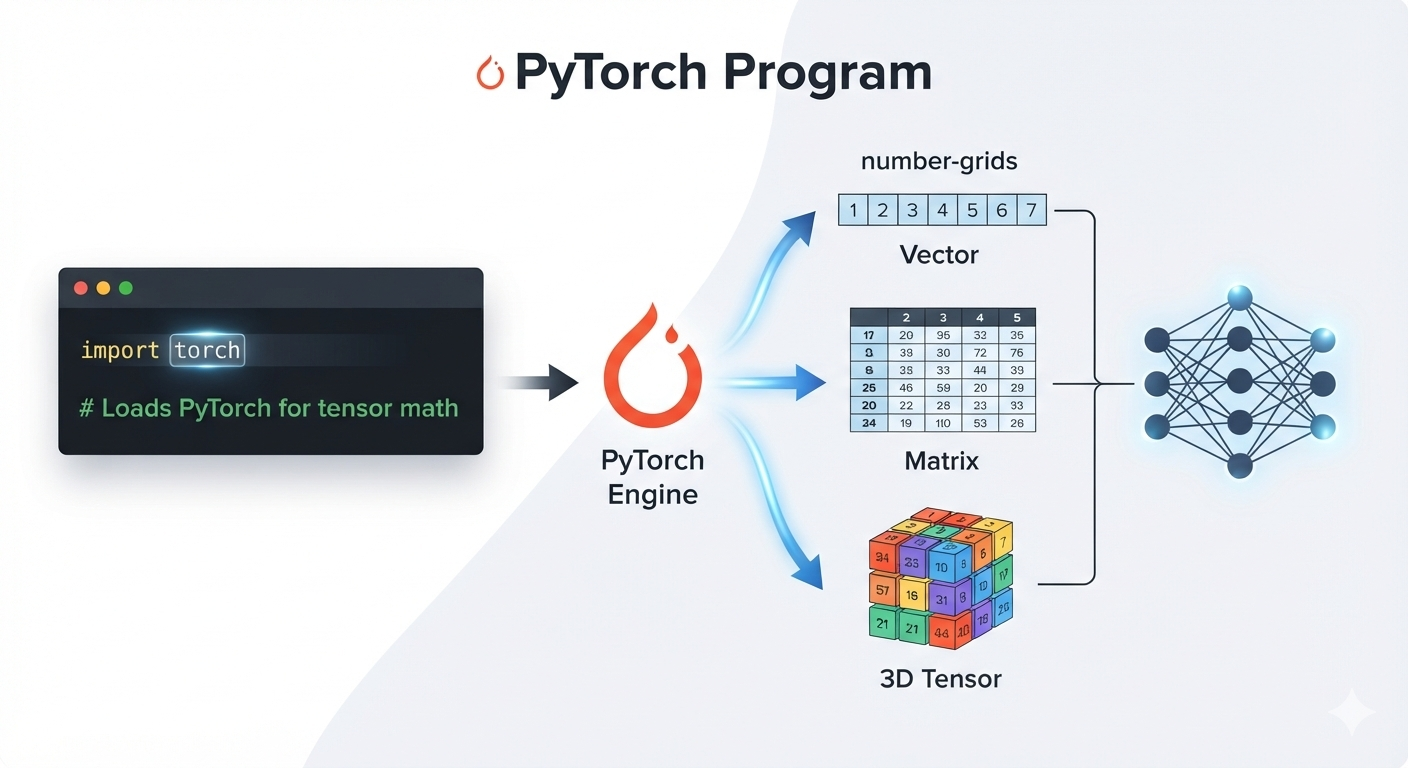

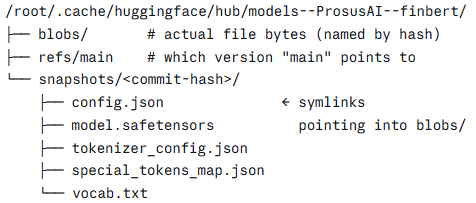

In [6]:
display(Image(filename=rf"{img_dir}image_1.png", width=1000))
display(Image(filename=rf"{img_dir}image_2.png", width=400))

In [7]:
from huggingface_hub import constants, scan_cache_dir
print(constants.HF_HUB_CACHE)      # exact cache path
print(scan_cache_dir())            # models cached + sizes
!du -sh ~/.cache/huggingface
!ls -R ~/.cache/huggingface/hub/models--ProsusAI--finbert | head -30

/root/.cache/huggingface/hub
HFCacheInfo(size_on_disk=438198538, repos=frozenset({CachedRepoInfo(repo_id='ProsusAI/finbert', repo_type='model', repo_path=PosixPath('/root/.cache/huggingface/hub/models--ProsusAI--finbert'), size_on_disk=438198538, nb_files=5, revisions=frozenset({CachedRevisionInfo(commit_hash='0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031', snapshot_path=PosixPath('/root/.cache/huggingface/hub/models--ProsusAI--finbert/snapshots/0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031'), size_on_disk=438198538, files=frozenset({CachedFileInfo(file_name='special_tokens_map.json', file_path=PosixPath('/root/.cache/huggingface/hub/models--ProsusAI--finbert/snapshots/0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031/special_tokens_map.json'), blob_path=PosixPath('/root/.cache/huggingface/hub/models--ProsusAI--finbert/blobs/e7b0375001f109a6b8873d756ad4f7bbb15fbaa5'), size_on_disk=112, blob_last_accessed=1794568736.4256973, blob_last_modified=1794568736.3656929), CachedFileInfo(file_name='model.safetenso

In [8]:
import os
from pathlib import Path
from huggingface_hub import constants, scan_cache_dir

# 1. Print Cache Location & Total Size
cache_info = scan_cache_dir()
print("=" * 65)
print(f"📁 HF Cache Path : {constants.HF_HUB_CACHE}")
print(f"💾 Total Size    : {cache_info.size_on_disk_str}")
print("=" * 65)

# 2. Print Cached Models Table
print(f"\n{'REPO ID':<38} | {'TYPE':<8} | {'SIZE':<10} | {'FILES'}")
print("-" * 65)
for repo in sorted(cache_info.repos, key=lambda r: r.size_on_disk, reverse=True):
    print(f"{repo.repo_id:<38} | {repo.repo_type:<8} | {repo.size_on_disk_str:<10} | {repo.nb_files}")

# 3. Print Clean Folder Tree for ProsusAI/finbert
model_dir = Path(constants.HF_HUB_CACHE) / "models--ProsusAI--finbert"
print(f"\n📂 Folder Structure ({model_dir.name}):")
if model_dir.exists():
    lines = []
    for root, dirs, files in os.walk(model_dir):
        level = root.replace(str(model_dir), "").count(os.sep)
        indent = "  " * level
        lines.append(f"{indent}├── {os.path.basename(root)}/")
        for f in files:
            lines.append(f"{indent}│   └── {f}")
    print("\n".join(lines[:30]))  # Limits output to first 30 lines
else:
    print("  Model directory not found in cache.")


📁 HF Cache Path : /root/.cache/huggingface/hub
💾 Total Size    : 438.2M

REPO ID                                | TYPE     | SIZE       | FILES
-----------------------------------------------------------------
ProsusAI/finbert                       | model    | 438.2M     | 5

📂 Folder Structure (models--ProsusAI--finbert):
├── models--ProsusAI--finbert/
  ├── refs/
  │   └── main
  ├── blobs/
  │   └── e7b0375001f109a6b8873d756ad4f7bbb15fbaa5
  │   └── e3d6323dc93e170f3eef66cebb32dbaf4589aee0
  │   └── cd79adc84d3c96daa03456853766c63141aef734
  │   └── fb140275c155a9c7c5a3b3e0e77a9e839594a938
  │   └── e5897858ff819aad7629b96ce521ae5477952d03634ef5dd30ed2d76357a9f00
  ├── .no_exist/
    ├── 0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031/
    │   └── tokenizer.json
    │   └── adapter_config.json
    │   └── added_tokens.json
    │   └── chat_template.jinja
  ├── snapshots/
    ├── 0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031/
    │   └── vocab.txt
    │   └── special_tokens_map.json
    │   └──

**This directory tree shows how Hugging Face organizes downloaded models on this disk** using a Git-like, content-addressed cache system. Instead of dumping files into one folder, Hugging Face separates version pointers, raw data, missing-file records, and readable shortcuts into four distinct folders.

### 1. `refs/` (Version Pointer)
* **`main`**: A tiny text file that stores the exact 40-character Git commit hash (`0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031`) of the latest version you downloaded from Hugging Face.
* **Purpose**: When you run `from_pretrained("ProsusAI/finbert")`, Hugging Face checks `refs/main` first to know which commit folder to load inside `snapshots/`.

### 2. `blobs/` (Actual File Data)
* **`e7b037...`, `e3d632...`, etc.**: These 5 files hold the actual bytes downloaded from the internet (including the 438 MB `model.safetensors` weights and text configs).
* **Purpose**: Each file is named using its cryptographic hash (SHA-1 or SHA-256). If two different model versions share the exact same `vocab.txt`, Hugging Face stores it only once in `blobs/` to save disk space.

### 3. `snapshots/` (Readable Folder View)
* **`0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031/`**: A folder named after the commit hash from `refs/main`.
* **The 5 files inside (`vocab.txt`, `config.json`, `model.safetensors`, etc.)**: These are symbolic links (symlinks / shortcuts), not duplicate copies. Each readable filename points directly to one of the 5 hashed files inside `blobs/`.
* **Purpose**: PyTorch and `transformers` read this folder so they can find files by standard names like `config.json` and `model.safetensors`.

### 4. `.no_exist/` (Negative Cache)
* **`tokenizer.json`, `adapter_config.json`, `added_tokens.json`, `chat_template.jinja`**: Empty marker files recording optional files that Hugging Face checked for on the server and confirmed do not exist in the `ProsusAI/finbert` repository.
* **Purpose**: Next time you load FinBERT, `transformers` sees these markers locally and skips making wasted network requests for files the model doesn't use (such as LoRA adapters or chat templates).

---

### Summary of How They Connect
When you call `AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert")`:

1. **Reads `refs/main`** $\rightarrow$ gets commit ID `0bc2ac10...`
2. **Opens `snapshots/0bc2ac10.../`** $\rightarrow$ finds `model.safetensors`
3. **Follows the symlink to `blobs/e5897858...`** $\rightarrow$ loads the 438 MB weights into RAM/GPU


In [9]:
from huggingface_hub import constants
print(constants.HF_HUB_CACHE)
# Output in Kaggle: /root/.cache/huggingface/hub

/root/.cache/huggingface/hub


### Use Kaggle’s Built-in Terminal

`cd /root/.cache/huggingface/hub`

`ls -lh`

#### 1. Check the actual size of the files inside blobs/
`ls -lh /root/.cache/huggingface/hub/blobs/`

#### 2. Check all folders and symlinks inside the hub directory
`ls -la /root/.cache/huggingface/hub/`

#### 3. View the readable filenames if the model folder exists
`ls -lh /root/.cache/huggingface/hub/models--ProsusAI--finbert/snapshots/*/`


## **Checek the Open WEIGHTS**
### See the Weight Files on Disk (Terminal or Code Cell)

When you ran ls -lh earlier, the download had just started. Now that model.safetensors is at 100%, 

run this command in your Kaggle terminal (>_) or a notebook cell:

`ls -lh /root/.cache/huggingface/hub/models--ProsusAI--finbert/snapshots/*/`

* **What you will see:** All 5 files listed in your screenshot, including model.safetensors pointing to the 438 MB file inside blobs/.
* **To make them appear in your right-hand Output panel:** Run model.save_pretrained("/kaggle/working/finbert") in a code cell and refresh /kaggle/working.


### Inspect the Loaded Weights Inside Python Memory (Loading weights: 100% 201/201)

The bottom progress bar (201/201) shows that PyTorch loaded all 201 weight tensors (matrices of numbers) directly into your model variable in memory. You can print and inspect those exact numbers using Python:


In [10]:
'''
list of every attribute, method, and neural network layer attached to your loaded Hugging Face model object 
(specifically, a BERT-based sequence classification model like FinBERT).
'''
# dir(model) ## includes hundreds of internal Python and PyTorch methods, it can be noisy.

'''Get only public methods (functions)'''
methods = [
    item for item in dir(model) 
    if not item.startswith("_") and callable(getattr(model, item))
]

# 2. Get only public attributes (layers, config, properties)
attributes = [
    item for item in dir(model) 
    if not item.startswith("_") and not callable(getattr(model, item))
]

print("ATTRIBUTES:", attributes)
print("\nMETHODS:", methods)


ATTRIBUTES: ['T_destination', 'all_tied_weights_keys', 'base_model_prefix', 'call_super_init', 'can_record_outputs', 'config', 'device', 'dtype', 'dummy_inputs', 'dump_patches', 'ep_plan', 'fsdp_plan', 'fsdp_size', 'input_modalities', 'is_distributed_loading_by_transformers', 'is_gradient_checkpointing', 'kernel_config', 'loss_type', 'main_input_name', 'model_tags', 'name_or_path', 'num_labels', 'pp_plan', 'supports_context_parallel', 'supports_gradient_checkpointing', 'supports_pp_plan', 'supports_tp_plan', 'tp_plan', 'tp_size', 'training', 'use_kernels']

METHODS: ['active_adapters', 'add_adapter', 'add_model_tags', 'add_module', 'apply', 'barrier_after_gathered_checkpoint_save', 'base_model', 'bert', 'bfloat16', 'buffers', 'can_generate', 'children', 'classifier', 'compile', 'config_class', 'cpu', 'cuda', 'delete_adapter', 'dequantize', 'disable_adapters', 'disable_input_require_grads', 'double', 'dropout', 'enable_adapters', 'enable_input_require_grads', 'enable_peft_hotswap', 'eva

In [11]:
print(model.config) ## to see the settings

BertConfig {
  "add_cross_attention": false,
  "architectures": [
    "BertForSequenceClassification"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "id2label": {
    "0": "positive",
    "1": "negative",
    "2": "neutral"
  },
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "label2id": {
    "negative": 1,
    "neutral": 2,
    "positive": 0
  },
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "tie_word_embeddings": true,
  "transformers_version": "5.20.2",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}



In [12]:
params_dict = dict(model.named_parameters())
params_list = list(model.named_parameters())

In [13]:
print(f"name: {params_list[0][0]} | Shape: ({len(params_list[0][1])},{len(params_list[0][1][1])})")

name: bert.embeddings.word_embeddings.weight | Shape: (30522,768)


In [14]:
print(params_list[0][1][1][1])
print(params_list[0][1][1][1].item())
type(params_list[0][1][1][1].item())

tensor(-0.0586, grad_fn=<SelectBackward0>)
-0.05862852931022644


float

In [15]:
import sys
# Size of the plain Python float returned by .item()
python_float = params_list[0][1][1][1].item()
print("Python float memory size:", sys.getsizeof(python_float), "bytes")  # Output: 24 bytes

# Size of that single number inside the PyTorch tensor
print("PyTorch tensor element size:", params_list[0][1][1][1].element_size(), "bytes")        # Output: 4 bytes (float32)

# Print Data Type & Full Precision: If by "size" you mean its bit-width (precision) or number of decimal digits:
print("Tensor data type:", params_list[0][1][1][1].dtype)        # Output: torch.float32 (32-bit)
print("Full precision value:", f"{params_list[0][1][1][1].item():.16f}")

Python float memory size: 24 bytes
PyTorch tensor element size: 4 bytes
Tensor data type: torch.float32
Full precision value: -0.0586285293102264



### Why the Sizes Differ

* Inside PyTorch (4 bytes): FinBERT weights are stored in torch.float32 (32-bit floating-point) format by default. Each individual weight takes exactly 4 bytes (or 2 bytes if loaded in float16/bfloat16).
* After .item() (24 bytes): Converting to a native Python float wraps the number in a standard 64-bit CPython object header, increasing its RAM footprint to 24 bytes.

In [16]:
# 1. Print all 201 layer names and their tensor shapes
for name, param in model.named_parameters():
    print(f"{name:<55} | Shape: {tuple(param.shape)}")

# 2. View the actual numerical weights of the final classifier layer (3 sentiment classes)
print("\nClassifier Weights (3x768):")
print(model.classifier.weight)


bert.embeddings.word_embeddings.weight                  | Shape: (30522, 768)
bert.embeddings.position_embeddings.weight              | Shape: (512, 768)
bert.embeddings.token_type_embeddings.weight            | Shape: (2, 768)
bert.embeddings.LayerNorm.weight                        | Shape: (768,)
bert.embeddings.LayerNorm.bias                          | Shape: (768,)
bert.encoder.layer.0.attention.self.query.weight        | Shape: (768, 768)
bert.encoder.layer.0.attention.self.query.bias          | Shape: (768,)
bert.encoder.layer.0.attention.self.key.weight          | Shape: (768, 768)
bert.encoder.layer.0.attention.self.key.bias            | Shape: (768,)
bert.encoder.layer.0.attention.self.value.weight        | Shape: (768, 768)
bert.encoder.layer.0.attention.self.value.bias          | Shape: (768,)
bert.encoder.layer.0.attention.output.dense.weight      | Shape: (768, 768)
bert.encoder.layer.0.attention.output.dense.bias        | Shape: (768,)
bert.encoder.layer.0.attention.outpu

In [17]:
# =====================================================================
# 1. DEEP DIVE: THE ALGORITHM (MODEL ARCHITECTURE)
# =====================================================================
print("\n🧩 === FINBERT ALGORITHM ARCHITECTURE ( neural network layers, run print(model)) ===")
print(model)


🧩 === FINBERT ALGORITHM ARCHITECTURE ( neural network layers, run print(model)) ===
BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768,

This text output is a structural blueprint of **FinBERT**, a specialized AI model used to classify financial text into 3 sentiment categories (**Positive**, **Negative**, or **Neutral**). When you print a PyTorch model in Python, it generates this exact nested tree to show every layer that data passes through from start to finish.

### How Data Flows Through This Blueprint

1. **`BertEmbeddings` (Turning Words into Numbers):** Computers cannot read text, so this section converts words into lists of 768 numbers.
   * **`word_embeddings(30522, 768)`:** A dictionary of 30,522 words, where each word is represented by 768 numerical traits.
   * **`position_embeddings(512, 768)`:** Tracks word order for sentences up to 512 words long so the model knows the difference between *"profits beat losses"* and *"losses beat profits."*
   * **`token_type_embeddings(2, 768)`:** Helps the model tell apart two different sentences when comparing them side-by-side.
   * **`LayerNorm` & `Dropout`:** Helpers that keep the numbers balanced and prevent the AI from memorizing training data too rigidly.

2. **`BertEncoder` (The 12 Thinking Layers):** This is the core brain of the model, consisting of 12 identical layers (`0-11`) stacked on top of each other.
   * **`BertSelfAttention` (query, key, value):** Allows every word to look at all other words in the sentence to figure out context. For example, it connects the word *"crushed"* to *"earnings"* rather than *"litigation."*
   * **`BertIntermediate` & `BertOutput`:** Expands the 768 numbers out to 3,072 numbers to process complex patterns, then compresses them back down to 768 before passing them to the next layer.

3. **`BertPooler` (Summarizing the Sentence):** After passing through all 12 layers, this step squishes the entire sentence's meaning into a single summary list of 768 numbers.

4. **`classifier` (Making the Final Decision):** The final `Linear(in_features=768, out_features=3)` layer takes those 768 summary numbers and boils them down into 3 final scores. These scores correspond to Positive, Negative, and Neutral financial sentiment.

---


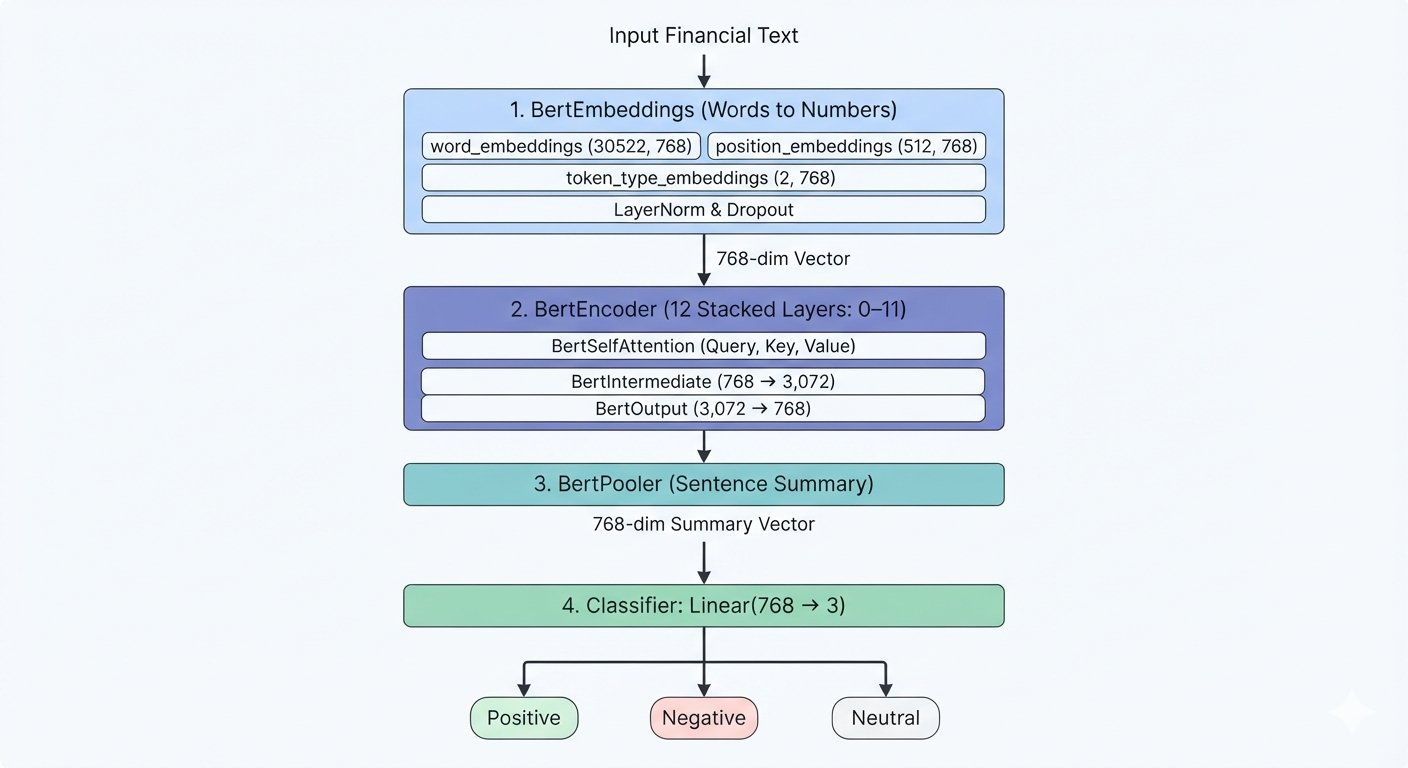

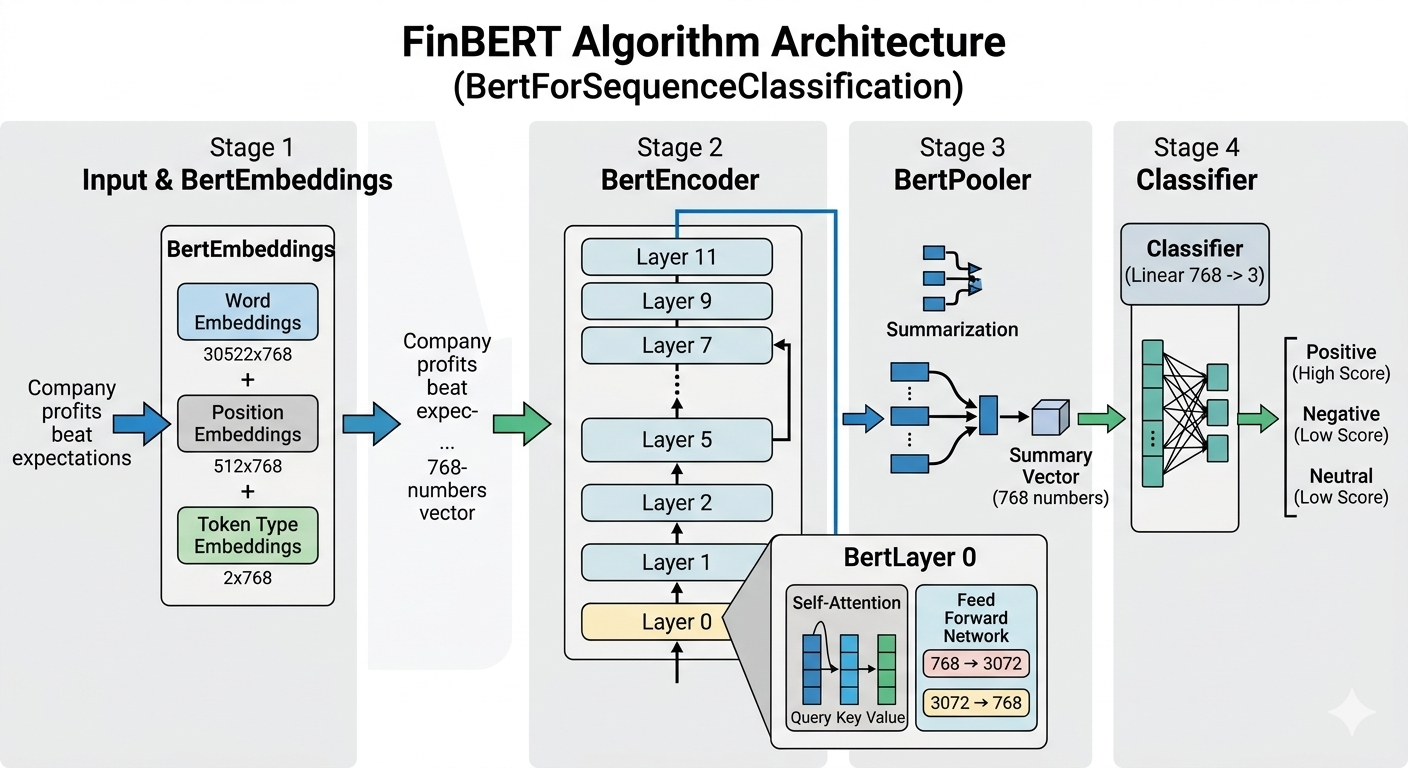

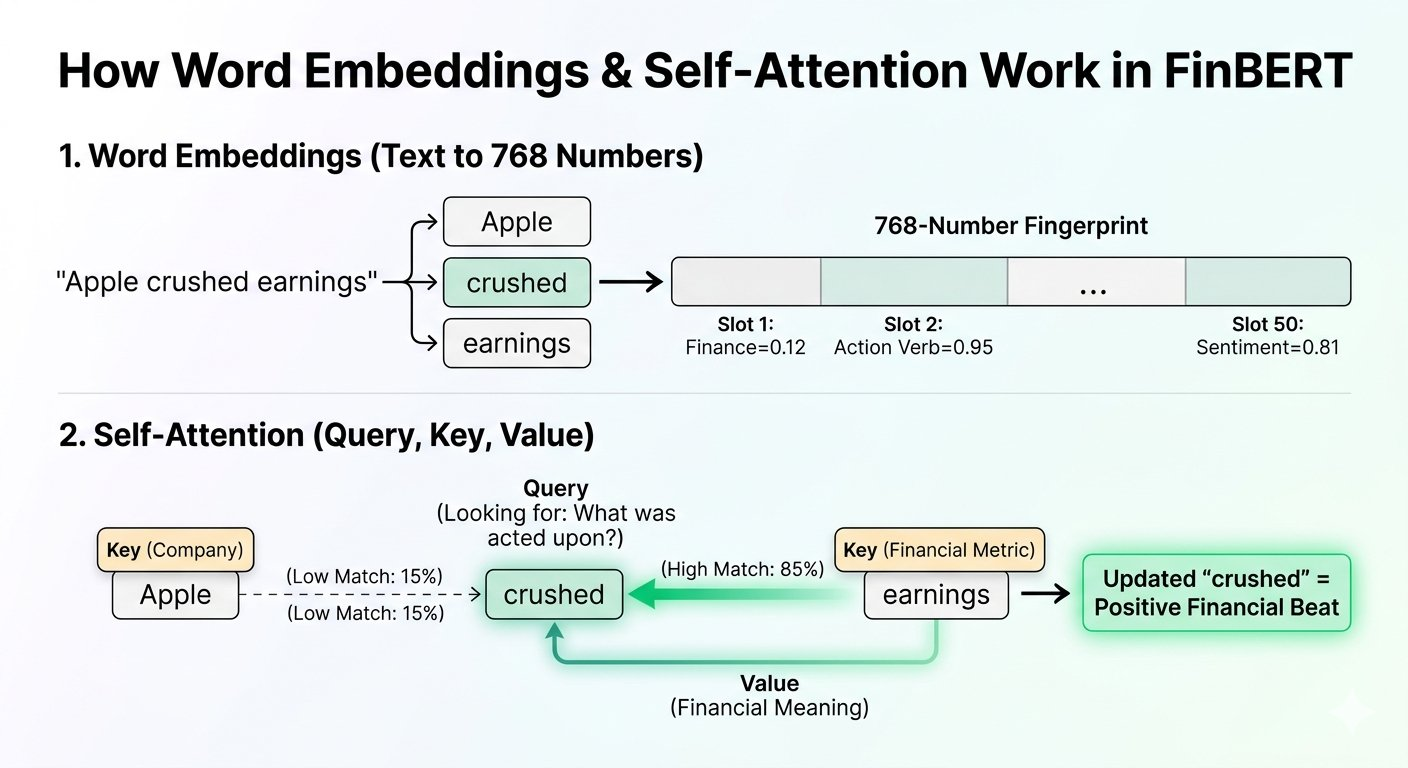

In [18]:
display(Image(filename=rf"{img_dir}image_3.png", width=1000))
display(Image(filename=rf"{img_dir}image_4.png", width=1000))
display(Image(filename=rf"{img_dir}image_5.png", width=1000))

In [19]:
# =====================================================================
# 2. DEEP DIVE: EXTRACTING THE CHOSEN LAYER WEIGHTS
# =====================================================================
print("\n📊 === TOTAL PARAMETER COUNT ===")
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters in FinBERT: {total_params:,}")


📊 === TOTAL PARAMETER COUNT ===
Total parameters in FinBERT: 109,484,547


In [20]:
print("\n⚙️ === EXTRACTING RAW WEIGHT TENSORS ===")
state_dict = model.state_dict()

# Print shapes of core components
print(f"Embedding Layer shape:     {state_dict['bert.embeddings.word_embeddings.weight'].shape}")
print(f"First Attention Layer (Q): {state_dict['bert.encoder.layer.0.attention.self.query.weight'].shape}")
print(f"Classification Head shape: {state_dict['classifier.weight'].shape}")

# Deep dive into the actual raw numbers of the Final Financial Classification Head
print("\n💎 === RAW MATRICES: THE CLASSIFICATION HEAD WEIGHTS ===")
print("These 3 vectors correspond to FinBERT's output labels (Positive, Negative, Neutral):")
print(model.classifier.weight.data)
print("\nClassification Head Biases:")
print(model.classifier.bias.data)


⚙️ === EXTRACTING RAW WEIGHT TENSORS ===
Embedding Layer shape:     torch.Size([30522, 768])
First Attention Layer (Q): torch.Size([768, 768])
Classification Head shape: torch.Size([3, 768])

💎 === RAW MATRICES: THE CLASSIFICATION HEAD WEIGHTS ===
These 3 vectors correspond to FinBERT's output labels (Positive, Negative, Neutral):
tensor([[-0.0039, -0.0037,  0.0097,  ..., -0.0065, -0.0223,  0.0118],
        [-0.0283,  0.0079,  0.0185,  ..., -0.0070, -0.0219,  0.0056],
        [-0.0068, -0.0424,  0.0288,  ..., -0.0313,  0.0462, -0.0226]])

Classification Head Biases:
tensor([ 0.0012, -0.0008, -0.0002])


In [21]:
# =====================================================================
# 3. INTERCEPTING INTERNAL MECHANICS (INFERENCE DEEP DIVE)
# =====================================================================
print("\n🧠 === INTERCEPTING INNER ALGORITHM MECHANICS ===")
financial_text = "The company reported a massive 25% increase in quarterly revenue."

model.set_attn_implementation("eager")

# Tokenize text into integers (Input IDs)
inputs = tokenizer(financial_text, return_tensors="pt")
print(f"Tokenized Input IDs: {inputs['input_ids']}")
print(f"Mapped Tokens:       {tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])}")

# Run inference while forcing the model to output its hidden states and attention matrices
with torch.no_grad():
    outputs = model(**inputs, output_hidden_states=True, output_attentions=True)

# Inspect the outputs
print(f"\nNumber of Hidden State Layers returned: {len(outputs.hidden_states)} (Embeddings + 12 BERT Layers)")
print(f"Shape of final layer hidden states:     {outputs.hidden_states[-1].shape}")
print(f"Number of Attention Matrices returned:   {len(outputs.attentions)} (One per BERT layer)")
print(f"Shape of Layer 1 Attention Map:         {outputs.attentions[0].shape} -> [Batch, Heads, Tokens, Tokens]")

# Softmax over logits to see final percentages
probabilities = torch.nn.functional.softmax(outputs.logits, dim=-1)
labels = ["Positive", "Negative", "Neutral"]
print("\n🏁 === FINAL FINANCIAL SENTIMENT PREDICTION ===")
for label, prob in zip(labels, probabilities[0].tolist()):
    print(f"• {label}: {prob*100:.2f}%")


🧠 === INTERCEPTING INNER ALGORITHM MECHANICS ===
Tokenized Input IDs: tensor([[  101,  1996,  2194,  2988,  1037,  5294,  2423,  1003,  3623,  1999,
         12174,  6599,  1012,   102]])
Mapped Tokens:       ['[CLS]', 'the', 'company', 'reported', 'a', 'massive', '25', '%', 'increase', 'in', 'quarterly', 'revenue', '.', '[SEP]']

Number of Hidden State Layers returned: 13 (Embeddings + 12 BERT Layers)
Shape of final layer hidden states:     torch.Size([1, 14, 768])
Number of Attention Matrices returned:   12 (One per BERT layer)
Shape of Layer 1 Attention Map:         torch.Size([1, 12, 14, 14]) -> [Batch, Heads, Tokens, Tokens]

🏁 === FINAL FINANCIAL SENTIMENT PREDICTION ===
• Positive: 95.15%
• Negative: 1.78%
• Neutral: 3.07%


In [22]:
# Run inference while explicitly forcing the model to output hidden states and attention matrices
with torch.no_grad():
    # Pass individual keys directly to guarantee the output flags are honored
    outputs = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        output_hidden_states=True,
        output_attentions=True
    )

# Inspect the outputs safely
print(f"\nNumber of Hidden State Layers returned: {len(outputs.hidden_states)} (Embeddings + 12 BERT Layers)")
print(f"Shape of final layer hidden states:     {outputs.hidden_states[-1].shape}")

if outputs.attentions is not None and len(outputs.attentions) > 0:
    print(f"Number of Attention Matrices returned:   {len(outputs.attentions)} (One per BERT layer)")
    print(f"Shape of Layer 1 Attention Map:         {outputs.attentions[0].shape} -> [Batch, Heads, Tokens, Tokens]")
else:
    print("⚠️ Attention matrices were not returned. Ensure transformers is up to date.")



Number of Hidden State Layers returned: 13 (Embeddings + 12 BERT Layers)
Shape of final layer hidden states:     torch.Size([1, 14, 768])
Number of Attention Matrices returned:   12 (One per BERT layer)
Shape of Layer 1 Attention Map:         torch.Size([1, 12, 14, 14]) -> [Batch, Heads, Tokens, Tokens]


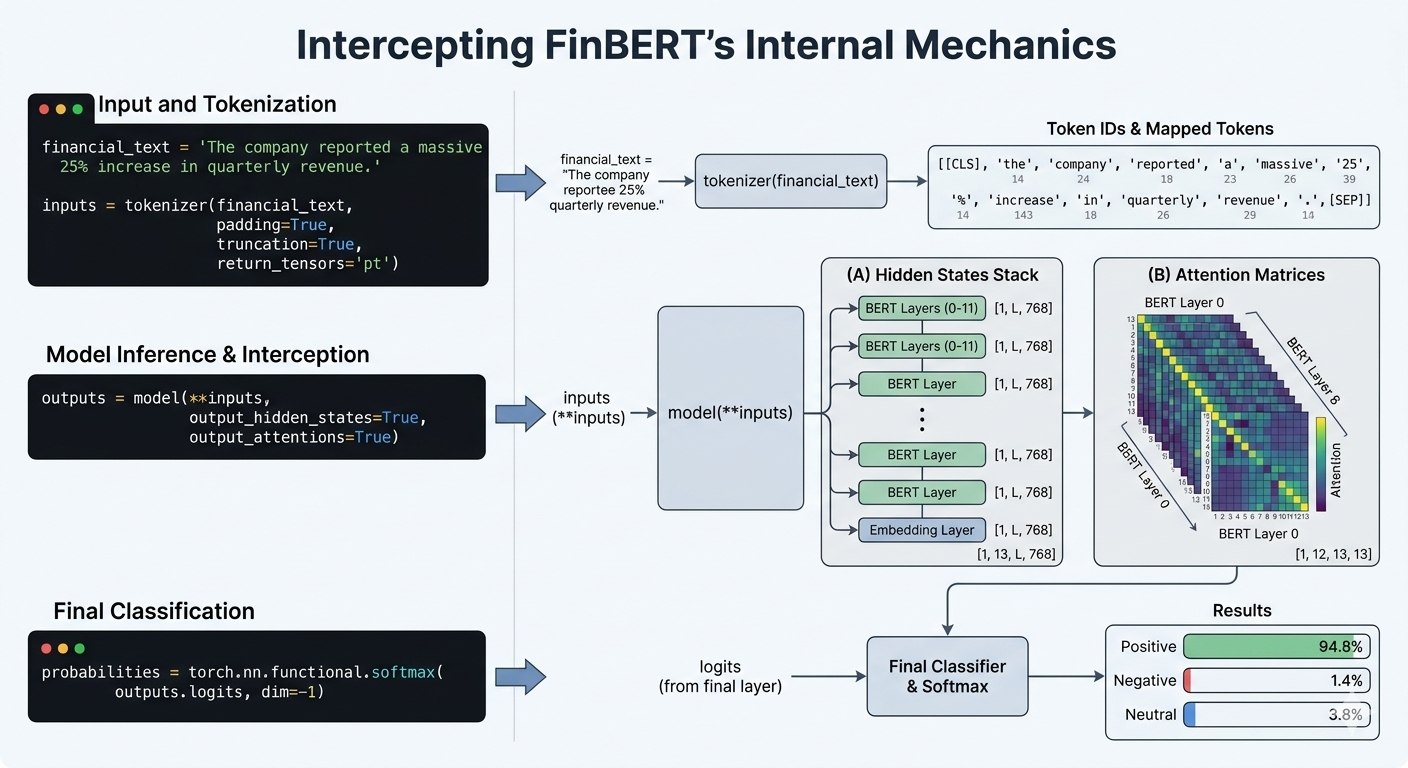

In [23]:
display(Image(filename=rf"{img_dir}image_6.jpg", width=1000))

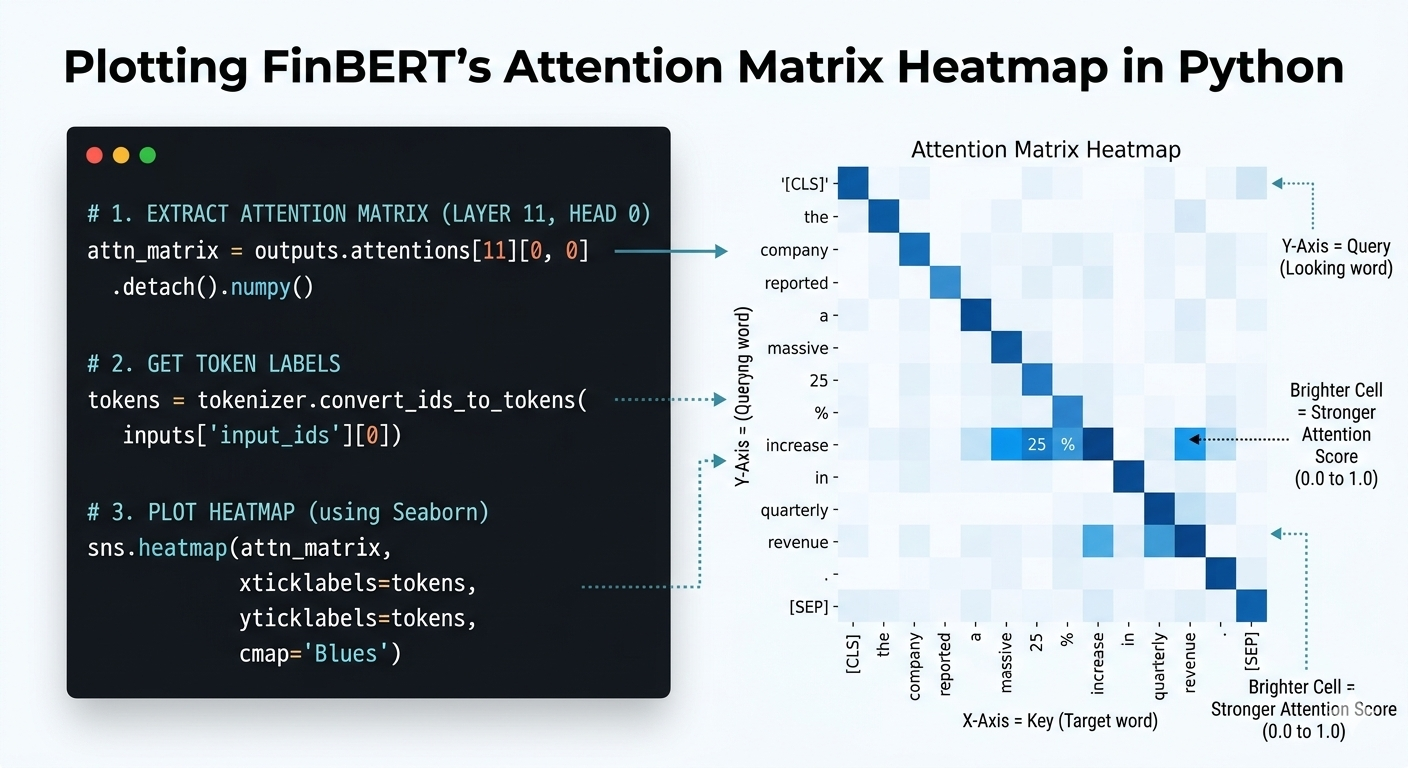

In [24]:
display(Image(filename=rf"{img_dir}image_7.jpg", width=1000))

In [25]:
import subprocess
import sys

try:
    from bertviz import head_view, model_view
    print("✅ BertViz is already installed!")
except ImportError:
    print("⏳ Installing BertViz...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "bertviz"])
    from bertviz import head_view, model_view
    print("✅ BertViz installed and imported successfully!")


⏳ Installing BertViz...
✅ BertViz installed and imported successfully!


In [26]:
# 2. Prepare your financial headline
financial_text = "The company reported a massive 25% increase in quarterly revenue."
inputs = tokenizer(financial_text, return_tensors="pt")

# 3. Explicitly pass output_attentions=True during inference
with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

# 4. Extract the first sentence's token IDs using [0]
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

# 5. Launch BertViz Head View
head_view(attention=outputs.attentions, tokens=tokens)

<IPython.core.display.Javascript object>

In [27]:
from IPython.display import display, HTML

# Generate the 12x12 Model View grid (12 Layers x 12 Heads = 144 mini-plots)
html_model_view = model_view(outputs.attentions, tokens, html_action='return')

# Render directly inside Kaggle's output window
display(HTML(html_model_view.data))